# A/B Test Analysis: Cookie Cats Gate Placement

**Context:** *Cookie Cats* is a mobile puzzle game. At certain levels players hit a **gate** and must either wait or pay to continue. The team tested moving the first gate from **level 30 (control)** to **level 40 (treatment)**.

**Question:** does moving the gate to level 40 change player **retention**, measured as playing 1 day and 7 days after install?

**Data:** 90,189 players randomly assigned to `gate_30` or `gate_40`.

**Hypotheses** (for each retention metric):
- H0: retention(gate_40) = retention(gate_30)
- H1: retention(gate_40) ≠ retention(gate_30), two-sided, α = 0.05

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

sns.set_theme(style="whitegrid"); CHARTS = "charts/"
df = pd.read_csv("data/cookie_cats.csv")
print(df.shape); df.head()

(90189, 5)


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## 1. Data checks

In [2]:
print("missing values:", df.isna().sum().sum(), "| duplicate userids:", df.userid.duplicated().sum())
df.describe()

missing values: 0 | duplicate userids: 0


,userid,sum_gamerounds
count,9.018900e+04,90189.000000
mean,4.998412e+06,51.872457
std,2.883286e+06,195.050858
min,1.160000e+02,0.000000
25%,2.512230e+06,5.000000
50%,4.995815e+06,16.000000
75%,7.496452e+06,51.000000
max,9.999861e+06,49854.000000


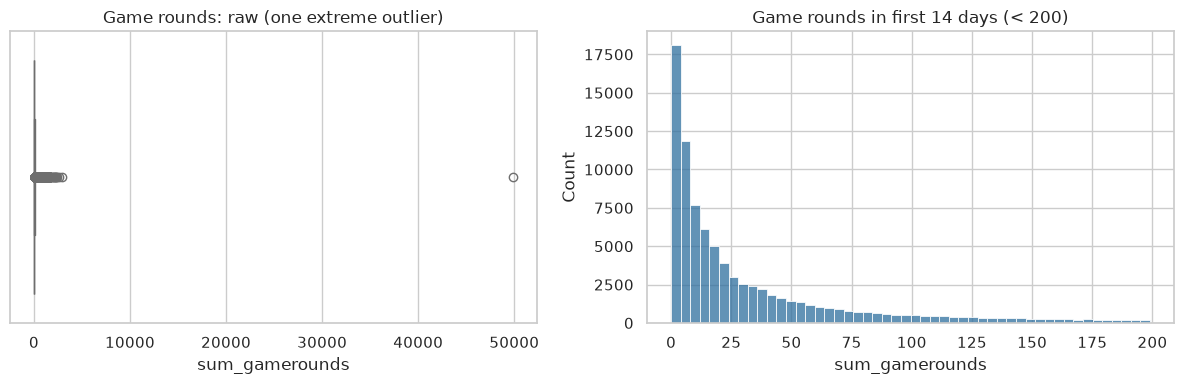

max rounds: 49854 | players with 0 rounds: 3994


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df["sum_gamerounds"], ax=ax[0], color="#9BB7D4"); ax[0].set_title("Game rounds: raw (one extreme outlier)")
sns.histplot(df.loc[df.sum_gamerounds < 200, "sum_gamerounds"], bins=50, ax=ax[1], color="#2E6F9E")
ax[1].set_title("Game rounds in first 14 days (< 200)")
plt.tight_layout(); plt.savefig(CHARTS + "gamerounds.png", dpi=110); plt.show()
print("max rounds:", df.sum_gamerounds.max(), "| players with 0 rounds:", (df.sum_gamerounds == 0).sum())

One player logged ~50,000 rounds in 14 days, far above everyone else. That's very likely a bot or a logging error, so it is removed. Players with 0 rounds are kept: they were assigned to a group, so dropping them would bias the test.

In [4]:
df = df[df.sum_gamerounds < df.sum_gamerounds.max()].copy()
len(df)

90188

## 2. Sample Ratio Mismatch (SRM) check
If randomisation worked, the two groups should be about 50/50. A chi-square goodness-of-fit test checks this.

In [5]:
counts = df.version.value_counts().sort_index()
chi2, p_srm = stats.chisquare(counts)
print(counts.to_dict()); print(f"split = {counts.iloc[0]/counts.sum():.2%} / {counts.iloc[1]/counts.sum():.2%}  |  chi2 = {chi2:.2f}, p = {p_srm:.4f}")

{'gate_30': 44699, 'gate_40': 45489}
split = 49.56% / 50.44%  |  chi2 = 6.92, p = 0.0085


The split is close to 50/50, but p < 0.05 means it is slightly unbalanced. A 0.7-point imbalance is small, so the analysis continues, but it is reported in the findings as a caveat.

## 3. Retention by group

In [6]:
summary = df.groupby("version").agg(players=("userid", "size"), retention_1=("retention_1", "mean"),
                                    retention_7=("retention_7", "mean"), median_rounds=("sum_gamerounds", "median"))
summary

,players,retention_1,retention_7,median_rounds
version,,,,
gate_30,44699,0.448198,0.190183,17.0
gate_40,45489,0.442283,0.182000,16.0


## 4. Statistical tests
A **two-proportion z-test** and a **chi-square test of independence** for each metric, plus 95% confidence intervals.

In [7]:
rows = []
for metric in ["retention_1", "retention_7"]:
    succ = df.groupby("version")[metric].sum().loc[["gate_30", "gate_40"]].values
    n = df.groupby("version")[metric].size().loc[["gate_30", "gate_40"]].values
    z, p = proportions_ztest(succ, n)
    chi2, p_chi, _, _ = stats.chi2_contingency(pd.crosstab(df.version, df[metric]))
    p30, p40 = succ / n
    diff = p40 - p30
    se = np.sqrt(p30 * (1 - p30) / n[0] + p40 * (1 - p40) / n[1])
    rows.append({"metric": metric, "gate_30": p30, "gate_40": p40, "abs_diff_pp": 100 * diff,
                 "rel_diff_pct": 100 * diff / p30, "ci95_low_pp": 100 * (diff - 1.96 * se),
                 "ci95_high_pp": 100 * (diff + 1.96 * se), "z": z, "p_value_z": p, "p_value_chi2": p_chi,
                 "significant": p < 0.05})
tests = pd.DataFrame(rows).set_index("metric"); tests.round(4)

,gate_30,gate_40,abs_diff_pp,rel_diff_pct,ci95_low_pp,ci95_high_pp,z,p_value_z,p_value_chi2,significant
metric,,,,,,,,,,
retention_1,0.4482,0.4423,-0.5915,-1.3198,-1.2403,0.0572,1.7871,0.0739,0.0750,False
retention_7,0.1902,0.1820,-0.8183,-4.3028,-1.3263,-0.3103,3.1574,0.0016,0.0016,True


## 5. Bootstrap confidence intervals
A bootstrap is a non-parametric check on the z-test: resample players 10,000 times and look at the distribution of the retention difference.

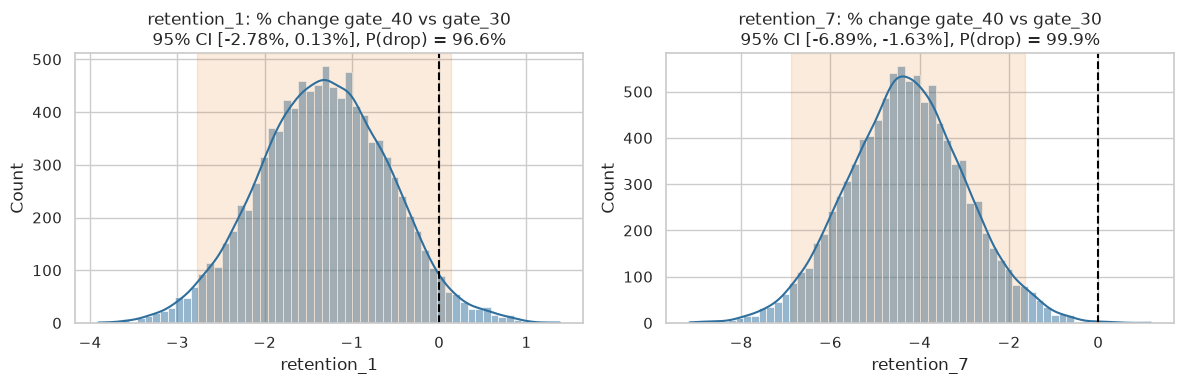

,retention_1,retention_7
count,10000.000,10000.000
mean,-1.322,-4.299
std,0.742,1.327
min,-3.904,-9.158
2.5%,-2.778,-6.889
97.5%,0.134,-1.632
max,1.384,1.180


In [8]:
rng = np.random.default_rng(42)
B = 10_000
g30 = df[df.version == "gate_30"]; g40 = df[df.version == "gate_40"]
boot = {}
for metric in ["retention_1", "retention_7"]:
    a = g30[metric].to_numpy(); b = g40[metric].to_numpy()
    ma = rng.binomial(len(a), a.mean(), B) / len(a)   # equivalent to resampling a Bernoulli column
    mb = rng.binomial(len(b), b.mean(), B) / len(b)
    boot[metric] = 100 * (mb - ma) / ma               # relative change of gate_40 vs gate_30, %
boot = pd.DataFrame(boot)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for axi, m in zip(ax, boot.columns):
    sns.histplot(boot[m], bins=60, ax=axi, color="#2E6F9E", kde=True)
    lo, hi = np.percentile(boot[m], [2.5, 97.5]); axi.axvline(0, color="black", ls="--")
    axi.axvspan(lo, hi, color="#E07A1F", alpha=0.15)
    axi.set_title(f"{m}: % change gate_40 vs gate_30\n95% CI [{lo:.2f}%, {hi:.2f}%], P(drop) = {(boot[m] < 0).mean():.1%}")
plt.tight_layout(); plt.savefig(CHARTS + "bootstrap.png", dpi=110); plt.show()
boot.describe(percentiles=[.025, .975]).round(3)

## 6. Engagement (game rounds)
Game rounds are heavily skewed, so groups are compared with a non-parametric **Mann-Whitney U test** rather than a t-test.

In [9]:
u, p_mw = stats.mannwhitneyu(g30.sum_gamerounds, g40.sum_gamerounds, alternative="two-sided")
print(f"median rounds: gate_30 = {g30.sum_gamerounds.median()}, gate_40 = {g40.sum_gamerounds.median()} | Mann-Whitney p = {p_mw:.4f}")

median rounds: gate_30 = 17.0, gate_40 = 16.0 | Mann-Whitney p = 0.0509


## 7. Power check
How big an effect could this test reliably detect? This matters for reading the day-1 result correctly.

In [10]:
n_per_group = len(df) / 2
analysis = NormalIndPower()
for metric in ["retention_1", "retention_7"]:
    base = tests.loc[metric, "gate_30"]
    for mde in [0.005, 0.01]:
        h = proportion_effectsize(base, base - mde)
        print(f"{metric}: power to detect a {100*mde:.1f}pp drop = {analysis.power(h, nobs1=n_per_group, alpha=0.05):.1%}")

retention_1: power to detect a 0.5pp drop = 32.7%
retention_1: power to detect a 1.0pp drop = 85.6%
retention_7: power to detect a 0.5pp drop = 48.5%
retention_7: power to detect a 1.0pp drop = 97.2%


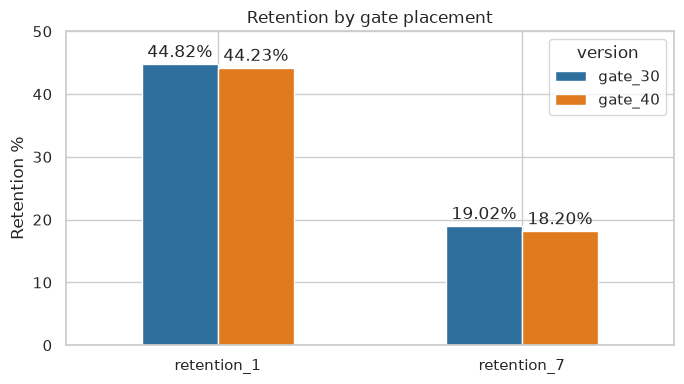

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
plot = summary[["retention_1", "retention_7"]].T * 100
plot.plot.bar(ax=ax, color=["#2E6F9E", "#E07A1F"], rot=0)
for c in ax.containers: ax.bar_label(c, fmt="%.2f%%", padding=2)
ax.set_ylabel("Retention %"); ax.set_title("Retention by gate placement"); ax.set_ylim(0, 50)
plt.tight_layout(); plt.savefig(CHARTS + "retention.png", dpi=110); plt.show()
tests.round(5).to_csv("outputs/test_results.csv"); summary.to_csv("outputs/group_summary.csv")

## 8. Conclusion
See the README for the final recommendation.